# Sujet 3 · Optimisation : gradient simple vs recuit simulé

**But.** Minimiser $h(x) = x^2 + 3x\cos x$ sur $[-8\pi, 8\pi]$ en partant de $x_0 = 7{,}5$, point
situé dans le bassin d'un minimum **local** non global, avec un algorithme déterministe (gradient)
puis un algorithme stochastique (recuit simulé), et comparer.

Énoncé : [enonce.md](enonce.md) · démonstrations complètes : [demonstrations.md](demonstrations.md) ·
Matlab → Python : [matlab_python.md](matlab_python.md) · code : `src/stats_td/optimisation.py`.
Graine 2026.

In [1]:
import json, sys, time
from pathlib import Path
sys.path.insert(0, str(Path("../../src").resolve()))

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from stats_td.figures import style, sauver, VIOLET, ROUGE, GRIS
from stats_td.optimisation import (BORNES_SUJET3, h_sujet3, dh_sujet3, pas_sujet3,
                                   gradient_simple, recuit_simule, minima_locaux)

style()
FIG = Path("figures")
rng = np.random.default_rng(2026)  # graine fixée : résultats reproductibles
resultats = {}
a, b = BORNES_SUJET3

## Q1 · La fonction $h$ sur $[-8\pi, 8\pi]$

$h'(x) = 2x + 3\cos x - 3x\sin x$ et $h''(x) = 2 - 6\sin x - 3x\cos x$ : le terme $3x\cos x$
oscille avec une amplitude $3|x|$ croissante, donc $h''$ change de signe et $h$ **n'est pas
convexe**. Comme $h(x) \ge |x|(|x| - 3) > 0$ pour $|x| > 3$ et que $h$ prend des valeurs
négatives, le minimum global est forcément dans $]-3, 3[$.

On discrétise sur 5000 points (`linspace`, voir la coquille de l'énoncé) et on prend `min` du
vecteur $h_n$.

dernier point de l'énoncé : 25.1227  (8π = 25.1327)
min sur la grille : h(-0.6385) = -1.1304   max : 707.1
9 minima locaux :
   x = -24.4446   h =  540.8934
   x = -18.1761   h =  287.7474
   x = -11.9234   h =  113.5399
   x =  -5.7392   h =   18.2061
   x =  -0.6371   h =   -1.1305   <- global
   x =   2.8051   h =   -0.0748
   x =   8.8137   h =   56.0253
   x =  15.0466   h =  190.7778
   x =  21.3093   h =  404.4521


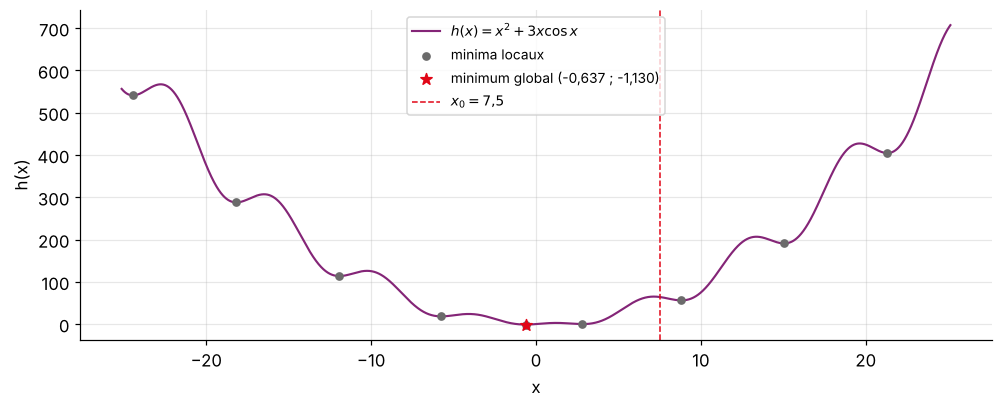

In [2]:
# Discrétisation de l'énoncé (y_n = -8π + 16π (n-1)/5000) et version qui atteint +8π
n = np.arange(1, 5001)
y_enonce = -8 * np.pi + 16 * np.pi * (n - 1) / 5000
y = np.linspace(a, b, 5000)            # = linspace Matlab : inclut les deux bornes
h_n = h_sujet3(y)
print(f"dernier point de l'énoncé : {y_enonce[-1]:.4f}  (8π = {8*np.pi:.4f})")

i = np.argmin(h_n)                      # min Matlab : [m, i] = min(h_n)
print(f"min sur la grille : h({y[i]:.4f}) = {h_n[i]:.4f}   max : {h_n.max():.1f}")

# Minima locaux exacts : zéros de h' encadrés par la grille, affinés par brentq
xm_grille, _ = minima_locaux(h_sujet3, a, b)
xm = np.array([brentq(dh_sujet3, x - 0.05, x + 0.05) for x in xm_grille])
hm = h_sujet3(xm)
X_GLOBAL = xm[np.argmin(hm)]
X_PIEGE = xm[np.argsort(hm)[1]]
X_LOCAL = brentq(dh_sujet3, 8.0, 9.5)   # minimum du bassin de x0 = 7,5
print(f"{len(xm)} minima locaux :")
for x, v in zip(xm, hm):
    print(f"   x = {x:8.4f}   h = {v:9.4f}" + ("   <- global" if x == X_GLOBAL else ""))

fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ax.plot(y, h_n, color=VIOLET, lw=1.4, label=r"$h(x)=x^2+3x\cos x$")
ax.scatter(xm, hm, color=GRIS, s=22, zorder=3, label="minima locaux")
ax.scatter([X_GLOBAL], [hm.min()], color=ROUGE, s=60, marker="*", zorder=4,
           label=f"minimum global ({X_GLOBAL:.3f} ; {hm.min():.3f})".replace(".", ","))
ax.axvline(7.5, color=ROUGE, ls="--", lw=1, label=r"$x_0 = 7{,}5$")
ax.set_xlabel("x"); ax.set_ylabel("h(x)")
ax.legend(fontsize=9, loc="upper center")
sauver(fig, FIG / "s31_h.png"); plt.show()

resultats["q1"] = {"n_minima": int(len(xm)), "x_global": float(X_GLOBAL), "h_global": float(hm.min()),
                   "x_piege": float(X_PIEGE), "h_piege": float(h_sujet3(X_PIEGE)),
                   "x_local_x0": float(X_LOCAL), "h_local_x0": float(h_sujet3(X_LOCAL))}

**Lecture.** $h$ a **9 minima locaux** sur l'intervalle. Le minimum global est
$x^\star \approx -0{,}637$, $h(x^\star) \approx -1{,}130$ ; le `min` de la grille le retrouve à
$0{,}002$ près (pas de grille $16\pi/4999 \approx 0{,}01$). Le minimum local le plus proche en
valeur est $x \approx 2{,}805$ ($h \approx -0{,}075$) : c'est le piège du recuit (Q4).
$x_0 = 7{,}5$ est entre les maxima $7{,}14$ et $13{,}37$, dans le bassin du minimum local
$x \approx 8{,}814$ ($h \approx 56{,}0$).

La discrétisation de l'énoncé s'arrête à $25{,}1227$ au lieu de $8\pi \approx 25{,}1327$ :
il faut diviser par 4999 (c'est ce que fait `linspace`).

## Q2 · Gradient simple

$x_n = x_{n-1} - \alpha_n h'(x_{n-1})$ pour $n \ge 1$ (numérotation qui évite $\alpha_0 = 0{,}025/0$),
avec $\alpha_n = 0{,}025/n$ : $\sum \alpha_n = +\infty$ (série harmonique, on peut aller aussi loin
que nécessaire) et $\sum \alpha_n^2 < \infty$ (les pas s'éteignent). Par Taylor,
$h(x - \alpha_n h'(x)) \le h(x) - \alpha_n h'(x)^2 (1 - \alpha_n M/2)$ avec $M$ un majorant de $h''$ sur
le segment ; ici $M \approx 20{,}2$, $\alpha_n \le 0{,}025$ : $h$ diminue strictement à chaque pas.

On note $\bar x \approx 8{,}814$ le minimum local du bassin de $x_0$ et $e_n = x_n - \bar x$ l'erreur.
Près de $\bar x$, $e_{n+1} \approx (1 - c/n)\,e_n$ avec $c = 0{,}025\,h''(\bar x)$, d'où
$|e_n| \approx C n^{-c}$ (démonstration dans [demonstrations.md](demonstrations.md#q2)).

x_0 = 7.5, h'(x_0) = -5.065  ->  x_1 = 7.6266
x_N = 8.6606, h(x_N) = 56.2483   (minimum local visé : 8.8137, h = 56.0253)
h décroît à chaque pas : True
   |x_n - x*| pour n =    100 : 0.4086
   |x_n - x*| pour n =   1000 : 0.1531
   |x_n - x*| pour n =  10000 : 0.0509
   |x_n - x*| pour n = 100000 : 0.0162
pente log-log mesurée : -0.494   théorie -c = -0,025 h''(x*) = -0.505


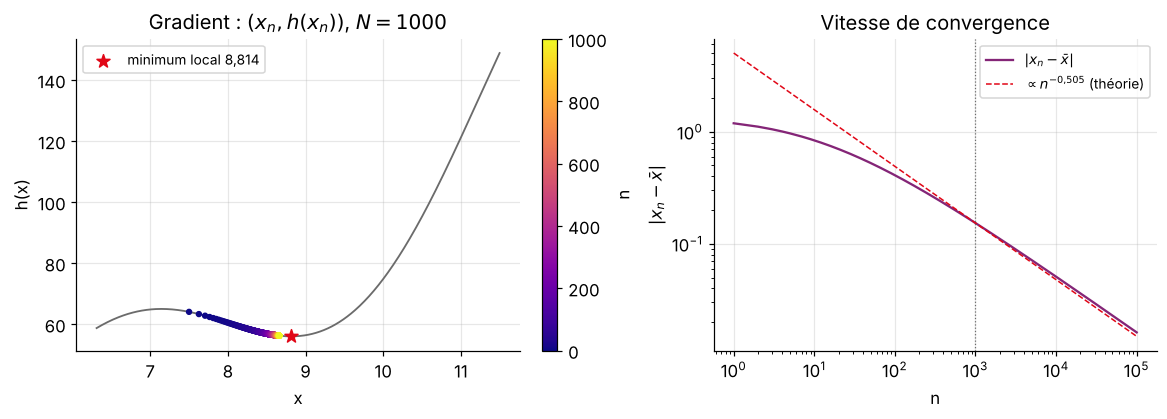

In [3]:
N = 1000
t0 = time.perf_counter()
xg = gradient_simple(dh_sujet3, 7.5, N)        # x_n = x_{n-1} - 0,025/n h'(x_{n-1})
duree_grad = time.perf_counter() - t0
print(f"x_0 = 7.5, h'(x_0) = {dh_sujet3(7.5):.3f}  ->  x_1 = {xg[1]:.4f}")
print(f"x_N = {xg[-1]:.4f}, h(x_N) = {h_sujet3(xg[-1]):.4f}   (minimum local visé : {X_LOCAL:.4f}, h = {h_sujet3(X_LOCAL):.4f})")
print("h décroît à chaque pas :", bool(np.all(np.diff(h_sujet3(xg)) <= 0)))

# Vitesse : on prolonge jusqu'à 10^5 itérations pour mesurer la pente de |x_n - x*|
xg_long = gradient_simple(dh_sujet3, 7.5, 100_000)
erreur = np.abs(xg_long - X_LOCAL)
for k in (100, 1000, 10_000, 100_000):
    print(f"   |x_n - x*| pour n = {k:>6} : {erreur[k]:.4f}")
c_theo = 0.025 * (2 - 6 * np.sin(X_LOCAL) - 3 * X_LOCAL * np.cos(X_LOCAL))
k = np.arange(1000, 100_001)
pente = np.polyfit(np.log(k), np.log(erreur[k]), 1)[0]
print(f"pente log-log mesurée : {pente:.3f}   théorie -c = -0,025 h''(x*) = {-c_theo:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained")
zoom = (y > 6.3) & (y < 11.5)
ax1.plot(y[zoom], h_n[zoom], color=GRIS, lw=1.2)
sc = ax1.scatter(xg, h_sujet3(xg), c=np.arange(N + 1), cmap="plasma", s=10, zorder=3)
ax1.scatter([X_LOCAL], [h_sujet3(X_LOCAL)], color=ROUGE, marker="*", s=80, zorder=4, label="minimum local 8,814")
ax1.set_xlabel("x"); ax1.set_ylabel("h(x)"); ax1.set_title(r"Gradient : $(x_n, h(x_n))$, $N = 1000$")
ax1.legend(fontsize=9); fig.colorbar(sc, ax=ax1, label="n")
nn = np.arange(1, 100_001)
ax2.loglog(nn, erreur[1:], color=VIOLET, lw=1.5, label=r"$|x_n - \bar x|$")
ax2.loglog(nn, erreur[1000] * (nn / 1000) ** (-c_theo), color=ROUGE, ls="--", lw=1,
           label=rf"$\propto n^{{-{c_theo:.3f}}}$ (théorie)".replace(".", "{,}"))
ax2.axvline(1000, color=GRIS, lw=0.8, ls=":")
ax2.set_xlabel("n"); ax2.set_ylabel(r"$|x_n - \bar x|$"); ax2.set_title("Vitesse de convergence"); ax2.legend(fontsize=9)
sauver(fig, FIG / "s32_gradient.png"); plt.show()

resultats["q2"] = {"N": N, "x_N": float(xg[-1]), "h_x_N": float(h_sujet3(xg[-1])),
                   "erreur_1000": float(erreur[1000]), "erreur_10000": float(erreur[10_000]),
                   "erreur_100000": float(erreur[100_000]), "pente_loglog": float(pente), "c_theorique": float(c_theo)}

**Lecture.** $h'(7{,}5) \approx -5{,}07 < 0$ : la suite part vers la droite et $h$ décroît à
chaque pas. Après $N = 1000$ itérations, $x_N \approx 8{,}661$ ($h \approx 56{,}25$) : on
**converge vers le minimum local** $8{,}814$ ($h \approx 56{,}03$), jamais vers le minimum global
($h \approx -1{,}13$). C'est attendu : partant de $x_0 = 7{,}5$, la descente ne peut pas
remonter le col en $7{,}14$.

La convergence est **lente** : il reste $0{,}153$ d'écart à $n = 1000$, puis $0{,}051$ et
$0{,}016$ à $n = 10^4$ et $10^5$ (facteur $\approx \sqrt{10}$ par décade). La pente mesurée en
log-log, $-0{,}494$, colle à la théorie $-c = -0{,}025\,h''(8{,}814) \approx -0{,}505$ :
l'erreur décroît en $1/\sqrt n$. Les « 1000 itérations » de l'énoncé suffisent pour **voir**
la convergence, pas pour l'atteindre à $10^{-3}$ près.

## Q3 · Recuit simulé

À chaque itération : $z \sim \mathcal U[x_n - \pi/2, x_n + \pi/2]$ ; on accepte $z$ avec
probabilité $\min(1, e^{-\Delta h_n/T_n})$, $\Delta h_n = h(z) - h(x_n)$, en pratique si
$U < e^{-\Delta h_n/T_n}$ avec $U \sim \mathcal U[0,1]$ (car $P(U < p) = p$). Températures
$T_n = 500 \times 0{,}99^n$. Choix d'implémentation : un $z$ hors de $[-8\pi, 8\pi]$ est refusé
(on minimise **sur l'intervalle**).

Pourquoi ça vise le global : à $T$ fixé, la chaîne a pour loi stationnaire
$\mu_T(x) \propto e^{-h(x)/T}$ (loi de Boltzmann ; équilibre détaillé, proposition symétrique), et
$\mu_T(x)/\mu_T(x^\star) = e^{-(h(x) - h(x^\star))/T} \to 0$ quand $T \to 0$ : la loi se
concentre sur les minima globaux.

x_N = -0.6503, h(x_N) = -1.1298   (minimum global : -0.6371, h = -1.1305)
meilleur point visité : -0.6334, h = -1.1304
T_n = 1 pour n = 618 ; T_N = 0.0216
taux d'acceptation par blocs de 100 itérations : [0.99 0.92 0.93 0.53 0.7  0.57 0.39 0.28 0.12 0.09]
dernière itération hors de ]x* - 0,5 ; x* + 0,5[ : n = 702


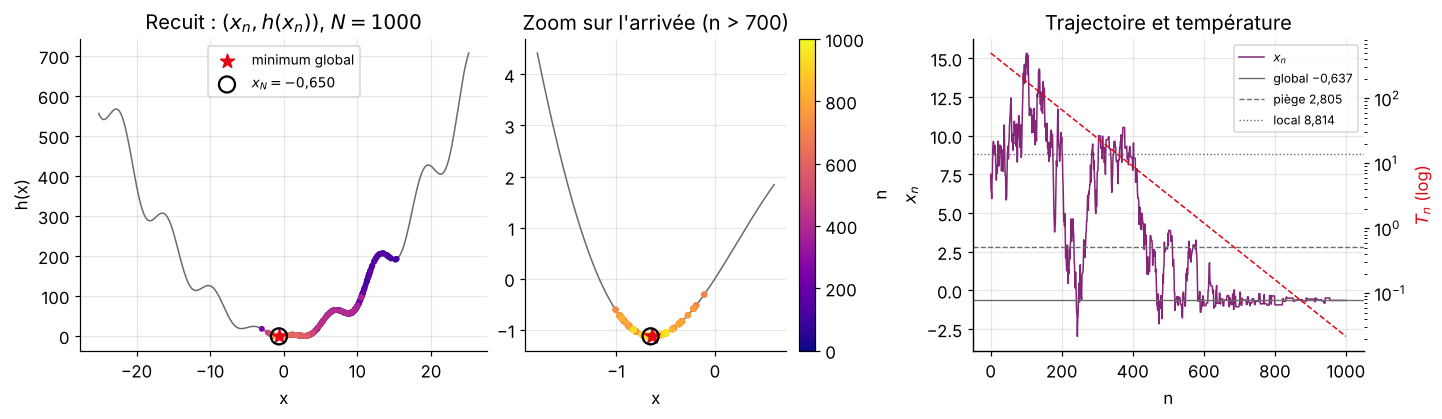

In [4]:
T0, ALPHA = 500.0, 0.99
t0 = time.perf_counter()
xr, acc = recuit_simule(h_sujet3, 7.5, N, rng, T0=T0, alpha=ALPHA, bornes=BORNES_SUJET3)
duree_recuit = time.perf_counter() - t0
Tn = T0 * ALPHA ** np.arange(N + 1)
meilleur = xr[np.argmin(h_sujet3(xr))]
print(f"x_N = {xr[-1]:.4f}, h(x_N) = {h_sujet3(xr[-1]):.4f}   (minimum global : {X_GLOBAL:.4f}, h = {hm.min():.4f})")
print(f"meilleur point visité : {meilleur:.4f}, h = {h_sujet3(meilleur):.4f}")
print(f"T_n = 1 pour n = {np.log(T0)/np.log(1/ALPHA):.0f} ; T_N = {Tn[-1]:.4f}")
print("taux d'acceptation par blocs de 100 itérations :", np.round(acc.reshape(10, 100).mean(axis=1), 2))
dernier_saut = np.max(np.nonzero(np.abs(xr - X_GLOBAL) > 0.5)[0]) if np.any(np.abs(xr - X_GLOBAL) > 0.5) else 0
print(f"dernière itération hors de ]x* - 0,5 ; x* + 0,5[ : n = {dernier_saut}")

fig, (ax1, axz, ax2) = plt.subplots(1, 3, figsize=(13, 3.7), layout="constrained",
                                    gridspec_kw={"width_ratios": [1.25, 0.8, 1.2]})
ax1.plot(y, h_n, color=GRIS, lw=1.0)
sc = ax1.scatter(xr, h_sujet3(xr), c=np.arange(N + 1), cmap="plasma", s=8, zorder=3)
ax1.scatter([X_GLOBAL], [hm.min()], color=ROUGE, marker="*", s=90, zorder=4, label="minimum global")
ax1.scatter([xr[-1]], [h_sujet3(xr[-1])], s=110, facecolors="none", edgecolors="k", lw=1.5, zorder=5,
            label=rf"$x_N = {xr[-1]:.3f}$".replace(".", "{,}"))
ax1.set_xlabel("x"); ax1.set_ylabel("h(x)"); ax1.set_title(r"Recuit : $(x_n, h(x_n))$, $N = 1000$")
ax1.legend(fontsize=9, loc="upper center")
# Zoom sur l'arrivée : les 300 dernières itérations autour du minimum global
zz = (y > -1.8) & (y < 0.6)
axz.plot(y[zz], h_n[zz], color=GRIS, lw=1)
axz.scatter(xr[-300:], h_sujet3(xr[-300:]), c=np.arange(N - 299, N + 1), cmap="plasma", vmin=0, vmax=N, s=12, zorder=3)
axz.scatter([X_GLOBAL], [hm.min()], color=ROUGE, marker="*", s=110, zorder=4)
axz.scatter([xr[-1]], [h_sujet3(xr[-1])], s=110, facecolors="none", edgecolors="k", lw=1.5, zorder=5)
axz.set_xlabel("x"); axz.set_title("Zoom sur l'arrivée (n > 700)")
fig.colorbar(sc, ax=axz, label="n")
ax2.plot(xr, color=VIOLET, lw=1.0, label=r"$x_n$")
for xx, lab, st in ((X_GLOBAL, "global −0,637", "-"), (X_PIEGE, "piège 2,805", "--"), (X_LOCAL, "local 8,814", ":")):
    ax2.axhline(xx, color=GRIS, ls=st, lw=0.9, label=lab)
ax2.legend(fontsize=8, loc="upper right")
ax2.set_xlabel("n"); ax2.set_ylabel(r"$x_n$")
ax3 = ax2.twinx(); ax3.semilogy(Tn, color=ROUGE, lw=1, ls="--"); ax3.set_ylabel(r"$T_n$ (log)", color=ROUGE)
ax3.grid(False); ax2.set_title("Trajectoire et température")
sauver(fig, FIG / "s33_recuit.png"); plt.show()

resultats["q3"] = {"T0": T0, "alpha": ALPHA, "N": N, "x_N": float(xr[-1]), "h_x_N": float(h_sujet3(xr[-1])),
                   "meilleur": float(meilleur), "T_N": float(Tn[-1]),
                   "taux_acceptation_blocs": [float(v) for v in acc.reshape(10, 100).mean(axis=1)]}

**Lecture.** Le recuit **atteint le minimum global** : le zoom (figure du milieu) montre les
dernières itérations regroupées autour de $x^\star$, et le point final (cercle noir) est sur
l'étoile. Partie du même $x_0 = 7{,}5$, la trajectoire **sort du bassin** du minimum local :
tant que $T_n$ est grand, les montées sont acceptées (taux $0{,}99$ sur les 100 premières
itérations) et la suite explore environ $[-3 ; 15{,}3]$. Quand $T_n$ passe sous 1 (vers $n = 618$), elle se
fixe : dernière sortie de $]x^\star - 0{,}5, x^\star + 0{,}5[$ à $n = 702$, puis le taux
d'acceptation tombe à $0{,}09$. Au final $x_N \approx -0{,}650$, $h(x_N) \approx -1{,}1298$,
contre $h(x^\star) \approx -1{,}1305$ : le recuit a trouvé le **minimum global** (meilleur point
visité : $-0{,}633$). La précision finale est limitée car les propositions restent larges
($\pm\pi/2$) même à basse température.

## Q4 · Comparaison quantitative

Même point de départ $x_0 = 7{,}5$, même nombre d'itérations $N = 1000$ : on compare les deux
trajectoires obtenues (le gradient de la Q2, le recuit de la Q3) sur des critères chiffrés. Le
bassin du minimum global est l'intervalle entre les deux cols qui l'entourent, $]-4{,}086 ; 1{,}227[$.

                                                 gradient      recuit
x_N                                                 8.661     -0.6503
h(x_N)                                              56.25       -1.13
|x_N - x*|                                          9.298     0.01321
h(x_N) - h(x*)                                      57.38    0.000622
meilleur h - h*                                     57.38   4.983e-05
entrée définitive dans le bassin du global         jamais         617
1er n avec h - h* < 0,05                           jamais         250
évaluations de fonction                        1000 de h'  <= 1001 de h
montées acceptées                                       0         266
temps de calcul (ms, médiane de 20)                  0.65        2.32


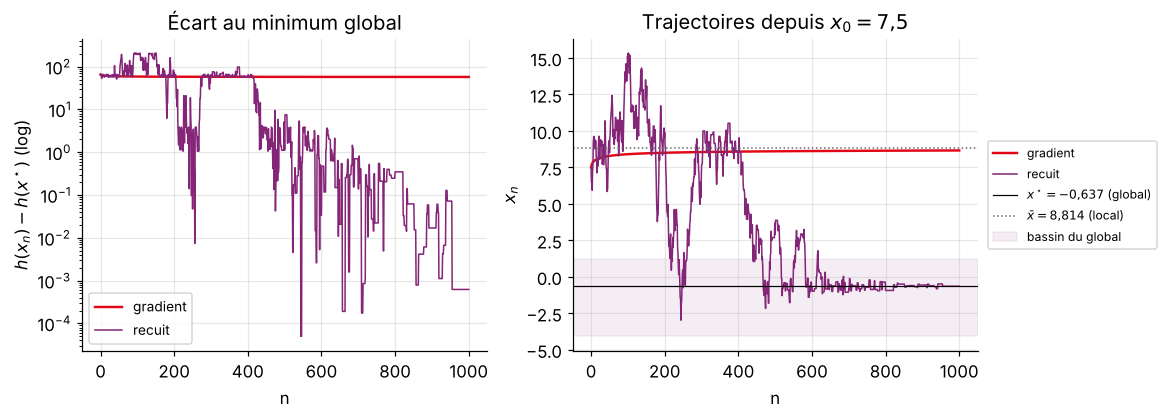

In [5]:
import timeit
h_star = hm.min()
M1 = brentq(dh_sujet3, -4.5, -3.5); M2 = brentq(dh_sujet3, 1.0, 1.5)   # cols qui bordent le bassin du global

def bilan(x):
    hx = h_sujet3(x)
    dans = (x > M1) & (x < M2)                       # dans le bassin du minimum global ?
    entree = int(np.max(np.nonzero(~dans)[0]) + 1) if dans[-1] else None
    proche = np.nonzero(hx - h_star < 0.05)[0]
    return {"x_N": x[-1], "h(x_N)": hx[-1], "|x_N - x*|": abs(x[-1] - X_GLOBAL),
            "h(x_N) - h(x*)": hx[-1] - h_star, "meilleur h - h*": hx.min() - h_star,
            "entrée définitive dans le bassin du global": entree,
            "1er n avec h - h* < 0,05": int(proche[0]) if len(proche) else None}

# Temps de calcul : médiane de 20 exécutions (générateur à part pour ne pas toucher à rng)
t_grad = np.median(timeit.repeat(lambda: gradient_simple(dh_sujet3, 7.5, N), number=1, repeat=20))
rng_temps = np.random.default_rng(0)
t_rec = np.median(timeit.repeat(lambda: recuit_simule(h_sujet3, 7.5, N, rng_temps, bornes=BORNES_SUJET3),
                                number=1, repeat=20))
B_g, B_r = bilan(xg), bilan(xr)
print(f"{'':45s}{'gradient':>12s}{'recuit':>12s}")
for cle in B_g:
    fmt = lambda v: "jamais" if v is None else (f"{v:.4g}" if isinstance(v, float) else str(v))
    print(f"{cle:45s}{fmt(B_g[cle]):>12s}{fmt(B_r[cle]):>12s}")
print(f"{'évaluations de fonction':45s}{'1000 de h' + chr(39):>12s}{'<= 1001 de h':>14s}")
print(f"{'montées acceptées':45s}{'0':>12s}{int(np.sum(np.diff(h_sujet3(xr)) > 0)):>12d}")
print(f"{'temps de calcul (ms, médiane de 20)':45s}{t_grad*1e3:12.2f}{t_rec*1e3:12.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained")
nn = np.arange(N + 1)
ax1.semilogy(nn, h_sujet3(xg) - h_star, color=ROUGE, lw=1.6, label="gradient")
ax1.semilogy(nn, h_sujet3(xr) - h_star, color=VIOLET, lw=1.0, label="recuit")
ax1.set_xlabel("n"); ax1.set_ylabel(r"$h(x_n) - h(x^\star)$ (log)")
ax1.set_title("Écart au minimum global"); ax1.legend(fontsize=9)
ax2.plot(nn, xg, color=ROUGE, lw=1.6, label="gradient")
ax2.plot(nn, xr, color=VIOLET, lw=1.0, label="recuit")
ax2.axhline(X_GLOBAL, color="k", ls="-", lw=0.8, label=r"$x^\star = -0{,}637$ (global)")
ax2.axhline(X_LOCAL, color=GRIS, ls=":", lw=1, label=r"$\bar x = 8{,}814$ (local)")
ax2.axhspan(M1, M2, color=VIOLET, alpha=0.08, label="bassin du global")
ax2.set_xlabel("n"); ax2.set_ylabel(r"$x_n$"); ax2.set_title("Trajectoires depuis $x_0 = 7{,}5$")
ax2.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
sauver(fig, FIG / "s34_comparaison.png"); plt.show()

resultats["q4"] = {"gradient": {k: (None if v is None else float(v)) for k, v in B_g.items()},
                   "recuit": {k: (None if v is None else float(v)) for k, v in B_r.items()},
                   "montees_acceptees": int(np.sum(np.diff(h_sujet3(xr)) > 0)),
                   "taux_acceptation": float(acc.mean()),
                   "temps_gradient_ms": float(t_grad * 1e3), "temps_recuit_ms": float(t_rec * 1e3),
                   "bassin_global": [float(M1), float(M2)]}

**Lecture.** Depuis le même $x_0 = 7{,}5$, avec le même budget de 1000 itérations :

| critère | gradient | recuit |
|---|---|---|
| point final $x_N$ | $8{,}661$ | $-0{,}650$ |
| $h(x_N)$ | $56{,}25$ | $-1{,}1298$ |
| écart au minimum global $h(x_N) - h(x^\star)$ | $57{,}38$ | $6{,}2 \times 10^{-4}$ |
| distance $\lvert x_N - x^\star\rvert$ | $9{,}30$ | $0{,}013$ |
| bassin du minimum global atteint | jamais | dès $n = 250$ ($h - h^\star < 0{,}05$), définitivement à $n = 617$ |
| précision vers sa propre cible | $\lvert x_N - \bar x\rvert = 0{,}153$ | $\lvert x_N - x^\star\rvert = 0{,}013$ |
| montées acceptées | 0 ($h$ baisse à chaque pas) | 266 (taux d'acceptation global 0,55) |
| évaluations | 1000 de $h'$ | au plus 1001 de $h$, + 2000 tirages |
| temps de calcul | de l'ordre de 1 ms | quelques ms (4 à 7 fois plus selon les exécutions) |

- **Résultat** : l'écart final au minimum global passe de $57{,}4$ (gradient) à $6 \times 10^{-4}$
  (recuit), soit environ $10^5$ fois moins. Le gradient reste dans le bassin de départ ; le recuit
  le quitte (premières montées dès les premières itérations), touche le bon bassin vers $n = 250$
  et s'y fixe à partir de $n = 617$, quand $T_n$ passe sous 1.
- **Vitesse** : le gradient converge de façon régulière mais lente ($n^{-0{,}5}$, encore $0{,}153$ du
  minimum local à $n = 1000$) ; le recuit progresse par à-coups (courbe de gauche, échelle log), puis
  se stabilise une fois froid.
- **Coût** : par itération, une évaluation dans les deux cas ; le recuit ajoute deux tirages
  uniformes et le test d'acceptation, d'où un temps plus long, qui reste de quelques millisecondes.
- **Compréhension et mise en œuvre** : le gradient s'écrit en une ligne avec un seul réglage (le
  pas) mais il faut connaître $h'$ ; le recuit n'utilise que $h$, mais demande trois réglages
  ($T_0$, $\alpha$, largeur de $g_n$) et son analyse fait appel aux chaînes de Markov. Comme il est
  aléatoire, un autre tirage donne une autre trajectoire (voir la réserve ci-dessous).

### Q4 (suite) · Plusieurs points de départ

Même expérience depuis 12 points de départ répartis sur l'intervalle (1000 itérations chacun ; pour
le gradient, le minimum visé est identifié en prolongeant à $10^5$ itérations).

    x0 | gradient x_N min. visé        h | recuit x_N    h - h*
   -22 |      -18.178   -18.176   287.75 |     -0.643  1.31e-04
   -15 |      -11.933   -11.923   113.54 |     -0.682  7.16e-03
    -9 |       -5.878    -5.739    18.21 |     -0.669  3.68e-03
    -5 |       -5.638    -5.739    18.21 |     -0.656  1.29e-03
    -2 |       -0.922    -0.637    -1.13 |      2.883  1.08e+00
     0 |       -0.418    -0.637    -1.13 |     -0.721  2.53e-02
     2 |        2.474     2.805    -0.07 |     -0.700  1.42e-02
     5 |        3.059     2.805    -0.07 |      2.798  1.06e+00
   7.5 |        8.661     8.814    56.03 |     -0.688  9.45e-03
    12 |        8.852     8.814    56.03 |     -0.695  1.20e-02
    18 |       15.048    15.047   190.78 |      2.794  1.06e+00
    24 |       21.309    21.309   404.45 |     -0.706  1.72e-02
gradient : minimum local atteint 12/12, minimum global 2/12
recuit   : minimum global 9/12, ailleurs : [2.883 2.798 2.794]
part de [-8π, 8π] dans le bassin du global : 

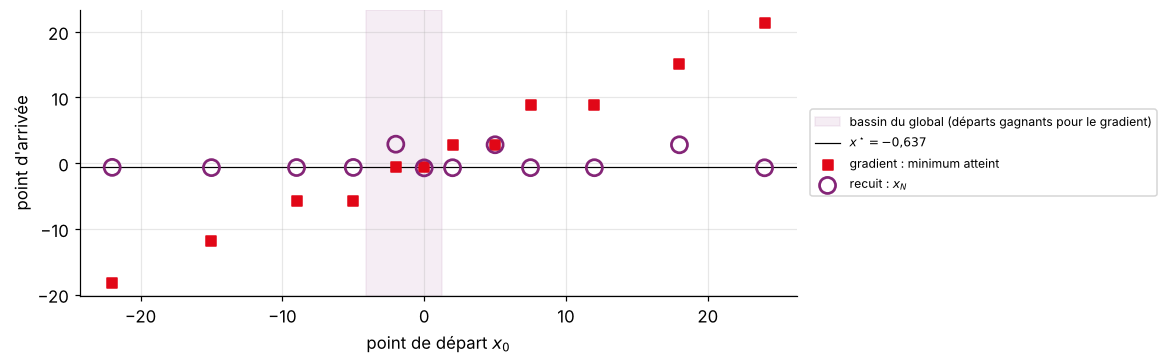

3091

In [6]:
# Plusieurs points de départ. Générateur à part (même graine) pour ne pas décaler rng.
departs = [-22, -15, -9, -5, -2, 0, 2, 5, 7.5, 12, 18, 24]
rng_dep = np.random.default_rng(2026)
fin_grad, cible_grad, fin_rec = [], [], []
for x0 in departs:
    xg0 = gradient_simple(dh_sujet3, x0, N)
    x_lim = gradient_simple(dh_sujet3, x0, 100_000)[-1]          # pour identifier le minimum visé
    fin_grad.append(xg0[-1]); cible_grad.append(xm[np.argmin(np.abs(xm - x_lim))])
    fin_rec.append(recuit_simule(h_sujet3, x0, N, rng_dep, bornes=BORNES_SUJET3)[0][-1])
fin_grad, cible_grad, fin_rec = map(np.array, (fin_grad, cible_grad, fin_rec))
glob_g = np.abs(cible_grad - X_GLOBAL) < 0.5
glob_r = np.abs(fin_rec - X_GLOBAL) < 0.5
print(f"{'x0':>6} | {'gradient x_N':>12} {'min. visé':>9} {'h':>8} | {'recuit x_N':>10} {'h - h*':>9}")
for x0, g, c, r in zip(departs, fin_grad, cible_grad, fin_rec):
    print(f"{x0:6} | {g:12.3f} {c:9.3f} {h_sujet3(c):8.2f} | {r:10.3f} {h_sujet3(r) - h_star:9.2e}")
print(f"gradient : minimum local atteint {len(departs)}/{len(departs)}, minimum global {glob_g.sum()}/{len(departs)}")
print(f"recuit   : minimum global {glob_r.sum()}/{len(departs)}, ailleurs : {np.round(fin_rec[~glob_r], 3)}")
print(f"part de [-8π, 8π] dans le bassin du global : {(M2 - M1) / (b - a):.3f}")

fig, ax = plt.subplots(figsize=(10.5, 3.2), layout="constrained")
ax.axvspan(M1, M2, color=VIOLET, alpha=0.08, label="bassin du global (départs gagnants pour le gradient)")
ax.axhline(X_GLOBAL, color="k", lw=0.8, label=r"$x^\star = -0{,}637$")
ax.scatter(departs, cible_grad, color=ROUGE, marker="s", s=40, zorder=3, label="gradient : minimum atteint")
ax.scatter(departs, fin_rec, facecolors="none", edgecolors=VIOLET, marker="o", s=110, lw=1.8, zorder=4, label="recuit : $x_N$")
ax.set_xlabel(r"point de départ $x_0$"); ax.set_ylabel("point d'arrivée")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
sauver(fig, FIG / "s34b_departs.png"); plt.show()
resultats["q4_departs"] = {"departs": departs, "gradient_x_N": fin_grad.tolist(), "gradient_minimum_vise": cible_grad.tolist(),
                           "recuit_x_N": fin_rec.tolist(), "gradient_global": int(glob_g.sum()), "recuit_global": int(glob_r.sum()),
                           "part_bassin_global": float((M2 - M1) / (b - a))}
(FIG / "resultats.json").write_text(json.dumps(resultats, indent=2, ensure_ascii=False))

**Lecture.** Le gradient atteint un minimum local **à chaque fois** (12 sur 12) : celui du bassin
où il part (escalier rouge). Il n'atteint le minimum global que depuis $x_0 = -2$ et $x_0 = 0$, les
deux seuls départs situés dans le bassin du global, qui ne couvre que 10,6 % de l'intervalle.
Le recuit atteint le minimum global depuis 9 départs sur 12, y compris depuis $-22$ ou $24$, très
loin ; les 3 autres lancers ($x_0 = -2$, $5$, $18$) finissent dans le minimum local $2{,}80$, le
plus proche en valeur du global. À noter : depuis $x_0 = -2$, c'est l'inverse, le gradient trouve le global et ce
lancer du recuit le manque.

**Conclusion de l'exemple :** atteindre **un** minimum local est facile (le gradient le fait à
coup sûr, de n'importe où) ; atteindre **le** minimum global est bien plus dur : le gradient n'y
arrive que si l'on part déjà dans le bon bassin, et même le recuit, conçu pour cela, ne le garantit
pas à chaque lancer.

## Pour aller plus loin (réserve pour l'oral) · le recuit réussit-il à tous les coups ?

Non repris dans le rendu PDF. Le recuit est aléatoire : on le relance $R = 1000$ fois (même
générateur, qui continue) et on estime la proportion de lancers qui finissent au minimum global.

1000 lancers du recuit (N = 1000) :
   minimum global  : 0.738 ± 0.027 (IC 95 %)
   piège x = 2,805 : 0.259 ± 0.027
   ailleurs        : 0.003
gradient : 0 succès (déterministe : toujours 8.661)


variante alpha = 0,995, N = 2000 (400 lancers) : succès 0.770 ± 0.041
écart en erreurs-types : 1.27


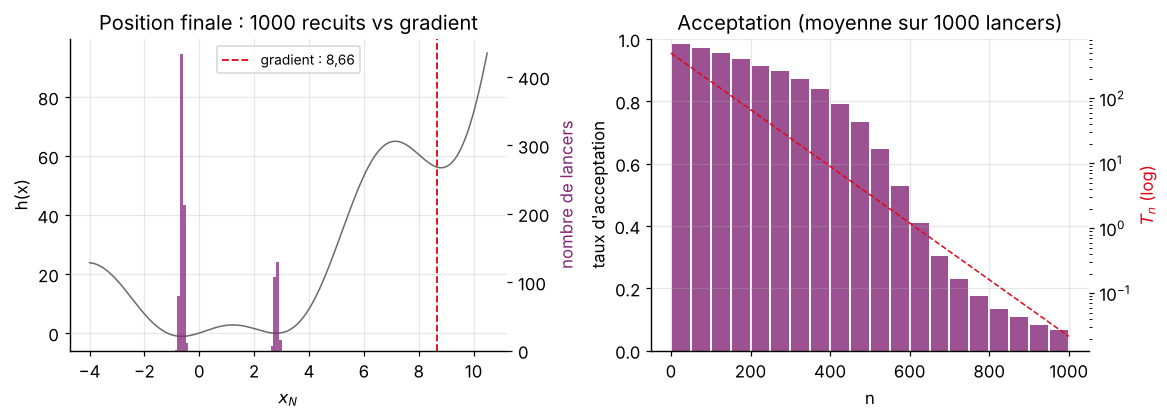

3531

In [7]:
R = 1000   # lancers indépendants (le générateur continue : chaque lancer a ses propres tirages)
t0 = time.perf_counter()
lancers = [recuit_simule(h_sujet3, 7.5, N, rng, T0=T0, alpha=ALPHA, bornes=BORNES_SUJET3) for _ in range(R)]
duree_R = time.perf_counter() - t0
fins = np.array([x[-1] for x, _ in lancers])
taux_acc = np.mean([acc_ for _, acc_ in lancers], axis=0)

def proportion(masque):
    p = masque.mean(); et = np.sqrt(p * (1 - p) / len(masque))
    return p, et

p_glob, et_glob = proportion(np.abs(fins - X_GLOBAL) < 0.5)
p_piege, et_piege = proportion(np.abs(fins - X_PIEGE) < 0.5)
p_autre = 1 - p_glob - p_piege
print(f"{R} lancers du recuit (N = {N}) :")
print(f"   minimum global  : {p_glob:.3f} ± {1.96*et_glob:.3f} (IC 95 %)")
print(f"   piège x = 2,805 : {p_piege:.3f} ± {1.96*et_piege:.3f}")
print(f"   ailleurs        : {p_autre:.3f}")
print(f"gradient : 0 succès (déterministe : toujours {xg[-1]:.3f})")

# Variante : refroidir deux fois plus lentement (alpha = 0,995, N = 2000)
R2 = 400
fins_lent = np.array([recuit_simule(h_sujet3, 7.5, 2000, rng, T0=T0, alpha=0.995, bornes=BORNES_SUJET3)[0][-1]
                      for _ in range(R2)])
p_lent, et_lent = proportion(np.abs(fins_lent - X_GLOBAL) < 0.5)
print(f"variante alpha = 0,995, N = 2000 ({R2} lancers) : succès {p_lent:.3f} ± {1.96*et_lent:.3f}")
print(f"écart en erreurs-types : {(p_lent - p_glob)/np.hypot(et_lent, et_glob):.2f}")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained")
zoom = (y > -4) & (y < 10.5)
ax1.plot(y[zoom], h_n[zoom], color=GRIS, lw=1.0)
ax1b = ax1.twinx()
ax1b.hist(fins, bins=np.linspace(-4, 10.5, 146), color=VIOLET, alpha=0.75)
ax1b.set_ylabel("nombre de lancers", color=VIOLET); ax1b.grid(False)
ax1.axvline(xg[-1], color=ROUGE, ls="--", lw=1.2, label=f"gradient : {xg[-1]:.2f}".replace(".", ","))
ax1.set_xlabel(r"$x_N$"); ax1.set_ylabel("h(x)")
ax1.set_title(f"Position finale : {R} recuits vs gradient"); ax1.legend(fontsize=9, loc="upper center")
blocs = taux_acc.reshape(20, 50).mean(axis=1)
ax2.bar(np.arange(20) * 50 + 25, blocs, width=45, color=VIOLET, alpha=0.8, label="taux d'acceptation moyen")
ax2.set_xlabel("n"); ax2.set_ylabel("taux d'acceptation"); ax2.set_ylim(0, 1)
ax3 = ax2.twinx(); ax3.semilogy(Tn, color=ROUGE, ls="--", lw=1); ax3.set_ylabel(r"$T_n$ (log)", color=ROUGE); ax3.grid(False)
ax2.set_title(f"Acceptation (moyenne sur {R} lancers)")
sauver(fig, FIG / "s36_1000_lancers.png"); plt.show()

resultats["reserve_1000_lancers"] = {"R": R, "succes_global": float(p_glob), "ic95_global": float(1.96 * et_glob),
                   "piege": float(p_piege), "ic95_piege": float(1.96 * et_piege), "ailleurs": float(p_autre),
                   "variante_alpha": 0.995, "variante_N": 2000, "variante_R": R2,
                   "variante_succes": float(p_lent), "variante_ic95": float(1.96 * et_lent),
                   "acceptation_debut": float(taux_acc[:100].mean()), "acceptation_fin": float(taux_acc[-100:].mean())}
(FIG / "resultats.json").write_text(json.dumps(resultats, indent=2, ensure_ascii=False))

**Lecture.** 73,8 % ± 2,7 % des lancers finissent au minimum global, 25,9 % restent dans le
minimum local $2{,}805$ (le deuxième plus bas, à seulement $1{,}06$ du global). Avec
$T_n = T_0\alpha^n$, $\sum_n e^{-d/T_n} < \infty$ : par Borel-Cantelli la chaîne gèle dans un bassin
aléatoire, donc l'affirmation de l'énoncé (« convergence presque sûre ») est fausse ; la garantie
de Hajek (en probabilité) demande $T_n = c/\ln n$. Refroidir plus lentement ($\alpha = 0{,}995$,
$N = 2000$) donne 77,0 % ± 4,1 % : écart de 1,27 erreur-type, non significatif. Détails dans
[demonstrations.md](demonstrations.md#q3).